# Feature visualization for pretrained CNNs using gradient ascent

This notebook investigates the generation of class-specific feature visualizations through gradient ascent on three pretrained convolutional neural networks (CNNs). It is organized into seven sections, beginning with an introduction to the two research questions and objectives, followed by environment setup and measures to ensure reproducibility, such as managing dependencies with Conda. Thereafter, the pretrained models (VGG-16, VGG-19, and ResNet-152) are loaded and verified, and the implementation of the gradient ascent algorithm as well as reusabile visualization and evaluation functions will be done. The two research questions are then investigated through separate experiments on cross-model transferability (RQ1) and the effects of optimization and regularization (RQ2). Finally, the results are presented and interpreted, leading into conclusions for the project.

## 1. Introduction and objectives

Convolutional neural networks (CNNs) perform well in image classification, but understanding which features they use for their predictions remains challenging. Gradient-ascent feature visualization can help explore these learned representations by generating images that strongly activate a specific class.

In this project, we will generate class-specific images using three pre-trained CNNs and investigate whether the images generated for each model also strongly activate the target class in the other two. By comparing two similar architectures (VGG-16 and VGG-19) with a more structurally different architecture (ResNet-152), we aim to examine the following research questions:

- **RQ1: Cross-model transferability.** To what extent do class-specific feature visualizations transfer between pretrained CNN models with similar and different architectures?

- **RQ2: Effect of optimization and regularization.** How do different gradient-ascent optimization and regularization methods affect the visual characteristics and cross-model transferability of the generated visualizations?

We hypothesize that visualizations will transfer better between VGG-16 and VGG-19 than between VGG and ResNet-152 as the former two are architecturally similar. The results will include quantitative measures of transferability, complemented by subjective visual comparisons of the generated images.

## 2. Setup, reproducibility and configuration

The following cells contain imports and constants used for the project. For reproducibility, all the neccessary dependencies are bundled in the Conda environments found in the `conda-environment-files` folder at the root of the project repository. The use of these environments is strongly recommended for anyone trying to run this notebook. Otherwise, ensure any and all necessary dependencies for the imports below are installed on your system. 

In [1]:
# --- IMPORTS --- #
import torch
from torchvision.models import vgg16, vgg19, resnet152, VGG16_Weights, VGG19_Weights, ResNet152_Weights
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torchvision.transforms.functional as TF

In [2]:
# --- CONSTANTS --- #
device = "cuda" if torch.cuda.is_available() else "cpu"


# --------------- Output device info --------------- #
print(f"Using device (cpu/cuda): {device}")
if device == "cuda":
    print(f"GPU being used: {torch.cuda.get_device_name(0)}" if torch.cuda.is_available() else "GPU being used: None")

Using device (cpu/cuda): cuda
GPU being used: NVIDIA GeForce RTX 4070


## 3. Load and verify the pretrained models

The following cell loads the VGG-16, VGG-19 and ResNet-152 models from the [torchvision.models](https://docs.pytorch.org/vision/stable/models.html) subpackage, with the `IMAGENET1K_V1` weights. Additionally, it sets all models to evaluation mode and freezes all parameters to avoid accidental manipulation of the pretrained model weights. The preprocessing transforms bundled for each of the models are also compared to check whether we can use the same transform for all models, which turned out to be true.

In [3]:
# Load pretrained models using ImageNet1K_V1 weights
vgg_16     = vgg16(weights=VGG16_Weights.IMAGENET1K_V1).to(device)
vgg_19     = vgg19(weights=VGG19_Weights.IMAGENET1K_V1).to(device)
resnet_152 = resnet152(weights=ResNet152_Weights.IMAGENET1K_V1).to(device)

# Load preprocessing transforms for each model
vgg_16_transform = VGG16_Weights.IMAGENET1K_V1.transforms()
vgg_19_transform = VGG19_Weights.IMAGENET1K_V1.transforms()
resnet_152_transform = ResNet152_Weights.IMAGENET1K_V1.transforms()

# Check that all three models use the same preprocessing, and output the transformations
same_transforms = str(vgg_16_transform) == str(vgg_19_transform) == str(resnet_152_transform)
print(f"All three models use the same transform: {same_transforms}")
print(vgg_16_transform)

# Ensure all parameters are frozen and all models are in eval mode,
# to ensure no dropouts are applied, etc.
for model in [vgg_16, vgg_19, resnet_152]:
    model.eval()
    for param in model.parameters():
        param.requires_grad = False

All three models use the same transform: True
ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


To ensure the models function as expected, they will all be tested on a clear [image of a goldfish](https://en.wikipedia.org/wiki/Goldfish#/media/File:Gold_fish1.jpg) taken from Wikipedia, to verify that the trained weights are properly applied, such that a correct prediction can be made. The following cell loads this image, displays it, and preprocesses it for inference.

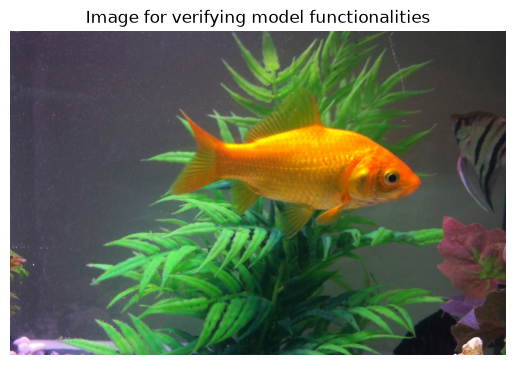

In [4]:
# Get sample image to test the models on to verify expected behavior
img_path = "../assets/WikipediaGoldfish.jpg"
img = Image.open(img_path).convert("RGB")

# Output image
plt.imshow(img)
plt.axis(False)
plt.title("Image for verifying model functionalities")
plt.show()

# Define transform for image. Vgg16 transform is used here, but is the same as Vgg19 and ResNet152's transform.
transform = vgg_16_transform

goldfish_tensor = transform(img).unsqueeze(0).to(device) # (1, 3, 224, 224)

With the pre-processed image of the goldfish, we can now do a forward pass for each of the three models, and check whether the predicted class matches the expected class label of 1 (goldfish) for the ImageNet dataset.

In [6]:
# Verify that the pretrained models work as expected for inference
goldfish_label = 1 # Class label in the ImageNet dataset.

with torch.no_grad():
    for name, model in [("VGG-16", vgg_16), ("VGG-19", vgg_19), ("ResNet-152", resnet_152)]:
        output = model(goldfish_tensor) # shape (1, 1000)
        pred = torch.argmax(output).item() # Predicted label
        
        prob = torch.softmax(output, dim=1)[0].max().item() * 100 # softmax over columns to get probability distribution for each class. Convert to %. 
        print(f"{name} predicted the class index: {pred} ({prob:.2f}% certainty) " + ("\t[CORRECT]" if pred == goldfish_label else "\t[INCORRECT]"))

VGG-16 predicted the class index: 1 (100.00% certainty) 	[CORRECT]
VGG-19 predicted the class index: 1 (100.00% certainty) 	[CORRECT]
ResNet-152 predicted the class index: 1 (99.26% certainty) 	[CORRECT]


## 4. Implement reusable functions

### 4.1 Image Tensor Visualization

The following functions intend to allow for easy processing and plotting of image tensor(s).

In [7]:
# Helper function which converts a tensor into an image and displays it
def tensor_to_image(image_tensor, plot=True, title=None):
    """Converts an image tensor into a numpy ndarray and plots it.

    Args:
        image_tensor (torch.Tensor): tensor with shape (num_channels, height, width) or (1, num_channels, height, width)
        title (str): Title text for the image plot

    Returns:
        np.ndarray: Image of shape (height, width, num_channels)
    """
    
    # Ensure input is of shape (num_channels, height, width) from here on
    if image_tensor.dim() == 4:
        image_tensor = image_tensor.squeeze(0)

    # Permute image dimensions from (num_channels, height, width) to (height, width, num_channels) to match matplotlib.imshow spec.
    img = image_tensor.permute(1, 2, 0).cpu().detach().numpy()

    # Clip image to range [0, 1] (matplotlib throws warning otherwise)
    img = np.clip(img, 0, 1)

    if plot:
        plt.imshow(img)
        if title:
            plt.title(title)
        plt.axis(False)
        plt.show()

    return img

In [8]:
# Helper function which converts two tensors into images and displays them side by side for comparison
def plot_tensor_pair(image_tensor1, image_tensor2, title1=None, title2=None, figsize=(10, 5)):
    """Converts two image tensors into a numpy ndarray and plots them together.

    Args:
        image_tensor1 (torch.Tensor): First tensor of shape (num_channels, height, width) or (1, num_channels, height, width)
        image_tensor2 (torch.Tensor): Second tensor of shape (num_channels, height, width) or (1, num_channels, height, width)
        title1 (str): Title text for the first image plot
        title2 (str): Title text for the second image plot
        figsize (tuple): Matplotlib figure size tuple

    Returns:
        tuple: (np.ndarray, np.ndarray) of shape (height, width, num_channels) for both images
    """
    
    # Process Tensor 1 as in function above
    if image_tensor1.dim() == 4:
        image_tensor1 = image_tensor1.squeeze(0)
    
    img1 = image_tensor1.permute(1, 2, 0).cpu().detach().numpy()
    img1 = np.clip(img1, 0, 1)

    # Process Tensor 2 as in function above
    if image_tensor2.dim() == 4:
        image_tensor2 = image_tensor2.squeeze(0)
        
    img2 = image_tensor2.permute(1, 2, 0).cpu().detach().numpy()
    img2 = np.clip(img2, 0, 1)

    # Plot both in the same subplot
    fig, ax = plt.subplots(1, 2, figsize=figsize)

    # First Image
    ax[0].imshow(img1)
    if title1:
        ax[0].set_title(title1)
    ax[0].axis(False)

    # Second Image
    ax[1].imshow(img2)
    if title2:
        ax[1].set_title(title2)
    ax[1].axis(False)

    plt.tight_layout()
    plt.show()

    return img1, img2

### 4.2 Gradient Ascent

To make it easier investigating RQ1 and RQ2 without introducing code repetition, the following helper `gradient_ascent` generates an image which maximally activates the class `target_label` for the provided `model`.

Traditional Gradient Descent is defined as a minimization problem with the goal to minimize the average loss.
For a model with parameters $\theta$, and a dataset of size $m$, the cost function $J(\theta)$
equivalates to the average loss across all samples.

$\nabla_{\theta} J (\theta) = \frac{1}{m} \sum^m_{i=1} \nabla_{\theta} L (f(x^{(i)};\theta), y^{(i)})$.

To minimize the loss, the following update rule is used to move in the opposite direction of the gradient 
in an attempt to change the parameters such that the loss is reduced:

$\theta := \theta - \alpha \nabla_{\theta} J (\theta)$.

For Gradient Ascent, we are no longer optimizing over the weights $\theta$ in the network, and those weights remain fixed.
Instead, we try to change pixels of some generic input image to maximize the class score. Thus this is a maximization problem:

$x := x + \alpha \nabla_x f (x)$

where $x$ are our input image pixels and $f$ the logit score of our targeted class, as $m = 1$ as we only optimize for the one input image, removing the need of an average as $J$ defines.

#### Adding L2 Regularization

Unregularized gradient ascent often results in high-frequency noise and chaotic artifacts because the network easily exploits individual pixel values. To generate a more coherent image, we can penalize the $L_2$ norm of the generated image, changing our objective $\arg \max_x f(x)$ to:

$\arg \max_x f(x) - \lambda \Vert x \Vert_2^2$.

where $\lambda$ is a hyperparameter that controls how heavy of a penalty should be applied. 

Taking the gradient of this objective with respect to $x$ (where the derivative of $\Vert{}x\Vert{}_2^2$ w.r.t. $x$ yields $2x$, which we can consider absorbed into the constant $\lambda$), the gradient ascent update rule becomes:

$x := x + \alpha \left( \nabla_x f(x) - \lambda x \right)$.

The result of adding $L_2$ regularization to gradient ascent is that individual pixels will not "explode" as much, as the optimization goal is one of maximization, and higher pixel values bring us further away from that goal by increasing the penalization term $\lambda \Vert x \Vert_2^2$. However, setting this constant too high might result in incredibly low pixel values, which makes the resulting image darker and less interpretable as well. Reasonably low values $\lambda$ should be used, as we sum the penalty of the squares of ***each and every pixel*** which yields large penalties even at low lambdas.

### Additional Regularization via Gaussian Blurring

Aditionally, as in [this paper](https://arxiv.org/pdf/1412.1897), a small blurring operator is added to allow regularizing the generated image not by penalizing high values, but by redistributing values between nearby pixels using a gaussian kernel to apply a blur by taking a weighted mean of nearby pixels. The implementation of this is simple using PyTorch's `torchvision.transforms.functional` subpackage, and merely makes use of a gaussian distribution, meaning each pixel is replaced by the weighted mean value of nearby pixels, with higher weight assigned to pixels with less spatial distance from the kernel's center pixel.

The result of applying Gaussian blurring is that noise and pixel extremities is reduced as the pixel values are smoothened based on nearby pixels (that are within the reach of the Gaussian kernel). The reason for adding this was that despite mitigating exploading values with L2 regularization, the output remained Noisy. Consequently this should result in an image that is more smooth rather than noisy, and potentially more visually cohesive for us humans. Whether this increases or decreases cross-model transferability remains to be seen.

In [9]:
# Gradient ascent optimization helper for generating input image which maximizes target class
def gradient_ascent(model, target_label, init_img_scale=0.001, lr=0.001, size=224, epochs=100, print_every=10, l2_lambda=0.0, gaussian_kernel_size=1):
    """Generates an input image tensor which maximizes the activation of the target class for `model`.

    Args:
        model: PyTorch model
        target_label (int): Class label to target optimization for during gradient ascent
        init_img_scale (float): Parameter which scales the initial (random) starting image to lower values for better stability.
        lr (float): Learning rate for the optimizer
        size (int): Square dimension of the generated image
        epochs (int): The number of epochs for the optimization of the generated image
        print_every (int): The epoch interval for printing progress
        l2_lambda (float): Hyperparameter which scales the magnitude of the penalization in L2-regularization
        gaussian_kernel_size (int): Kernel size for Gaussian blur smoothing on the image pixels. Must be odd-numbered. 1 means no blurring.

    Returns:
        torch.Tensor: Image tensor of shape (1, 3, size, size)
    """
    # Ensure gaussian kernel is odd-numbered (must have a center pixel)
    if gaussian_kernel_size % 2 == 0:
        raise ValueError("Gaussian Kernel size must be odd numbered.")
    
    # Ensure model is in evaluation mode as we do not wish to update weights during Gradient Ascent.
    model.eval()

    # Define mean and std for ImageNet dataset:
    mean = torch.tensor([0.485, 0.456, 0.406]).to(device).view(1, 3, 1, 1)
    std  = torch.tensor([0.229, 0.224, 0.225]).to(device).view(1, 3, 1, 1)

    # Starting image, which will be optimized to maximally activate `target_label` class.
    # (We activate gradient accumulation via autograd to find how the loss is affected by the input pixels!)
    x = torch.rand(1, 3, size, size).to(device) * init_img_scale
    x = x.requires_grad_(True)

    # Use Adam as optimizer, with parameters set to the input x. 
    # Configure Adam to compute as a maximization problem, as described earlier.
    optimizer = torch.optim.Adam([x], lr=lr, maximize=True)

    for epoch in range(epochs):
        # Reset gradients to not cause accumulation from prev. epoch.
        optimizer.zero_grad()

        # Noramlize x before doing a pass into the model
        x_normalized = (x - mean) / std

        # Forward pass
        output = model(x_normalized)

        # Target class logit score
        score = output[0][target_label]

        # Compute L2 penalty and overall objective (Score - lambda * ||x||_2^2)
        # Default l2_lambda value is 0.0, so unless explicitly set, L2 regularization penalty is 0.
        l2_penalty = l2_lambda * torch.sum(x ** 2)
        objective = score - l2_penalty

        # Backprop on the objective
        objective.backward()

        # Parameter update (i.e. Gradient Ascent update)
        optimizer.step()

        # Modify image post-gradient step. e.g. clip pixel values to [0,1] range, apply gaussian blur...
        with torch.no_grad():
            torch.clip_(x, 0, 1) # In-place update to not override the x tensor which tracks gradients.

            # Perform gaussian blurring. If default value 1 is used, it is equivalent to returning the same image, so we skip the blurring.
            if gaussian_kernel_size != 1:
                blurred = TF.gaussian_blur(x, kernel_size=gaussian_kernel_size)
                x.copy_(blurred)

        # Print progress every `print_every` epochs
        if (epoch + 1) % print_every == 0:
            with torch.no_grad():
                # Get probabilities via Softmax, extract probability for target class and convert to %. 
                prob = torch.softmax(output, dim=1)[0][target_label].item() * 100
                print(f"Epoch: {epoch + 1}/{epochs}. Target Logit Score: {score.item():.2f}. Target certainty: {prob:.2f}%")

    return x.detach()

### 4.3 Evaluation

We will evaluate cross-model transferability using top-1 and top-5 accuracy, treating the intended target class of each generated image as its true ground-truth label. We will also report the mean softmax score assigned to this class to assess how strongly each model favors it. Results will be compared across model pairs using a few selected classes and random image initializations. 

Optimization and regularization methods will be compared using identical starting images and a fixed number of optimization steps, including a baseline without regularization. Quantitative results will be complemented by visual inspection of a predefined image subset, where we assess recognizable class features.

The `evaluate` helper method intends to calculate not the accuracies and mean values, but the top-1 correctness, top-5 correctness, and the softmax score of a single image tensor for a model. It functions as a modular helper which can be used to either evaluate a single sample, or create more intricate evaluation loops for RQ1 and RQ2 as needed.

In [10]:
# Evaluation helper which takes image tensor as input, and performs forward pass on a model and extracts quantitative metrics
def evaluate(model, image_tensor, target_label):
    """Evaluates an unnormalized image tensor on a model for cross-model transferability.

    Args:
        model: PyTorch model
        image_tensor (torch.Tensor): Input image tensor with shape (batch, num_channels, width, height) to evaluate on `model`.
        target_label (int): The ground truth label for the target class

    Returns:
        dict: Contains top1_correct, top5_correct, softmax_score, and top1_pred.
    """
    model.eval()

    # Define mean and std for ImageNet dataset:
    mean = torch.tensor([0.485, 0.456, 0.406]).to(device).view(1, 3, 1, 1)
    std  = torch.tensor([0.229, 0.224, 0.225]).to(device).view(1, 3, 1, 1)

    with torch.no_grad():
        # Forward pass
        image_tensor_normalized = (image_tensor - mean) / std
        output = model(image_tensor_normalized)

        # Calculate probabilities via softmax
        probs = torch.softmax(output, dim=1) # (1, 1000)

        # Top-1 Accuracy
        (_, top1_idx) = torch.topk(probs, 1, dim=1) # (1, 1)
        top1_correct = (target_label == top1_idx[0][0].item())

        # Top-5 Accuracy
        (_, top5_idxs) = torch.topk(probs, 5, dim=1) # (1, 5)
        top5_correct = (target_label in top5_idxs[0].tolist())

        # Softmax Score for the class
        target_pred = probs[0][target_label].item() # Prediction for target class

    return {
        "top1_correct": top1_correct,
        "top5_correct": top5_correct,
        "softmax_score": target_pred,
        "top1_pred": top1_idx.item()
    }

## 5. RQ1 - Cross-model transferability

To evaluate cross-model transferability, a new helper `cross_model_transferability` is defined below, combining the use of `gradient_ascent` and `evaluate`, alongside (optionally) `tensor_to_image` to enable convenient access to performing the evaluations for different hyperparameters. This function takes as input a dictionary mapping model names to the models we wish to pairwise evaluate for each other's generated images, which are also passed as an input dictionary. 

Furthermore the helper takes as input an integer representing the number of images that *each* model should generate per class. A mean accuracy for top-1, top-5 predictions and the softmax scores are made, and returned. This way, we can easily prototype choices of hyperparameters prior to running large image batches to derive stable mean values for the model pairs.

In [11]:
# Helper function for doing the RQ1 cross-model transferability experiments
def cross_model_transferability(models_dict, target_classes, nr_images, init_img_scale=0.001, lr=0.001, epochs=20, print_every=10, l2_lambda=0.0, gaussian_kernel_size=1, plot_images=False):
    """Runs the RQ1 cross-model transferability experiment across specified models and classes.

    Args:
        models_dict (dict): Dictionary mapping model names to PyTorch model instances.
        target_classes (dict): Dictionary mapping class names to ImageNet class indices.
        nr_images (int): Number of images to generate per model & class, to then take mean of.
        init_img_scale (float): Parameter which scales the initial (random) starting image to lower values for better stability.
        lr (float): Learning rate for gradient ascent optimizer.
        epochs (int): Number of optimization epochs for gradient ascent.
        print_every (int): Interval for printing gradient ascent progress.
        l2_lambda (float): Hyperparameter which scales the magnitude of the penalization in L2-regularization
        gaussian_kernel_size (int): Kernel size for Gaussian blur smoothing on the image pixels. Must be odd-numbered. 0 means no blurring.
        plot_images (bool): Whether to plot the generated images using tensor_to_image.

    Returns:
        pd.DataFrame: A summary table containing cross-model evaluation metrics.
    """
    # List to hold all results (#models * #classes)
    results = []

    # Iterate through each model to generate images for each class, and evaluate on all models.
    for gen_name, gen_model in models_dict.items():
        for class_name, class_idx in target_classes.items():

            for img_nr in range(nr_images):
                if img_nr + 1 == nr_images: # Print progress for last image in range to avoid clutter
                    print(f"Generating {class_name} #({img_nr + 1}/{nr_images}) via {gen_name}")
                
                # Generate feature visualization using gradient ascent
                generated_img = gradient_ascent(
                    model=gen_model, 
                    target_label=class_idx,
                    init_img_scale=init_img_scale,
                    epochs=epochs, 
                    lr=lr, 
                    print_every=print_every,
                    l2_lambda=l2_lambda,
                    gaussian_kernel_size=gaussian_kernel_size
                )
                
                # Plot generated image if plot_images is set to true
                if plot_images and img_nr + 1 == nr_images: # Only plot last image in image batch for model
                    tensor_to_image(generated_img, plot=True, title=f"\"{class_name}\" generated via {gen_name}")
                
                # Cross-evaluate the generated image across all models
                for eval_name, eval_model in models_dict.items():
                    metrics = evaluate(eval_model, generated_img, class_idx)
                    
                    results.append({
                        "Generator Model": gen_name,
                        "Evaluator Model": eval_name,
                        "Target Class": class_name,
                        "Top-1 Correct": metrics["top1_correct"],
                        "Top-5 Correct": metrics["top5_correct"],
                        "Softmax Score": metrics["softmax_score"]
                    })

    # Convert results to DataFrame
    df = pd.DataFrame(results)

    # Define the metrics to average across
    metrics = ["Top-1 Correct", "Top-5 Correct", "Softmax Score"]
    
    # Group by model pairs and target class, filter by metrics to then calculate mean, and rename those columns
    df_meaned = (
        df.groupby(["Generator Model", "Evaluator Model", "Target Class"], as_index=False)[metrics]
          .mean()
          .rename(columns={col: f"Mean {col}" for col in metrics})
    )

    return df_meaned

To perform a concrete evaluation of transferability, without the use of regularizers, we initialize a dictionary `models_dict` containing the three target models, and another `target_classes` containing a few arbitrarily selected classes from the ImageNet dataset. We then use these with the helper defined above, omitting setting hyperparameters for any regularization terms, such that regularization is omitted.

Hyper-parameter tuning has been done manually and iteratively for a couple classes and images, until hyperparameters were found which we could not seem to improve much further without performing expensive and time-consuming grid searches. In particular, emphasis was placed on tuning the initial scale of the randomized image pixels (`init_img_scale`), the learning rate, and the number of epochs.

Notable remarks that were made during hyperparameter tuning in the case of unregularized gradient ascent were the following:
- Without regularization, increasing the number of epochs strictly increases the target logit score every epoch. This is expected as high pixel values are not penalized, and they can continuously grow to increase the target logit score.
- If very many epochs are performed, due to the above, the generated image overfit greatly to the peculiarities of the generator model, resulting in *only* that model being able to output predictions beyond what would otherwise be considered guessing.
- If the number of epochs is set much lower, such that distinct features are extracted but without the image severely overfitting to the peculiarities of the generator model, we can get different results. Notably, it is not very rare to see VGG-19 managing to get a top-1 or top-5 classification for an image generated by VGG-16. For certain "easier" classes, VGG-16 also manages to predict the output of VGG-19, albeit at lower softmax scores. Considering VGG-19 is a deeper extension of VGG-16 (with a few more convolutional blocks), it is reasonable to expect transferability from VGG-16 to VGG-19 to be slightly better than the reverse direction, as VGG-19 would generate a slightly "higher level" feature image which the features of VGG-16 might not be able to interpret as well.
- If we start with an image with higher pixel values (more noise), images generated by VGG-19 seem to sometimes be classified more easily by VGG-16 rather than the inverse. This could potentially be because VGG-16's shallower architecture make its optimization path more volatile, causing the pixels to explode and over-fit to its specific layers, worsening the cross-model transferability. In contrast, VGG-19's additional depth allows it to process the noise through additional higher-level features which could result in more generalized and transferable patterns. However, the result of starting with more noise makes the results look more like TV-static, whereas starting with lower noise levels creates some visible, yet unrecognizeable patterns in the noise. 

Ultimately, the result of performing gradient ascent without regularization on each model and evaluating cross-model transferability of the output feature images is that VGG-16 and VGG-19 are sometimes successful in interpreting each other's generated images, whereas ResNet152 is completely unable to interpret the output of the others, and vice versa. The softmax scores for when ResNet152 is the evaluator model indicates that at best, the model is just guessing, or is under belief that it is *not* the target class, and provides mean softmax scores of $< \frac{1}{1000}$. Similarily this is often the case for VGG-16 and VGG-19 as the evaluator models for an input generated by ResNet152.

Through a subjective visual analysis, we can also conclude that the generated images are for the most part nothing but uninterpretable noise, regardless of whether models like VGG-16 and VGG-19 achieve high cross-model transferability or not.

Generating Goldfish #(20/20) via VGG-16


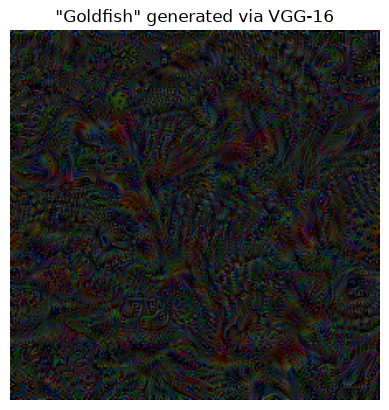

Generating Flamingo #(20/20) via VGG-16


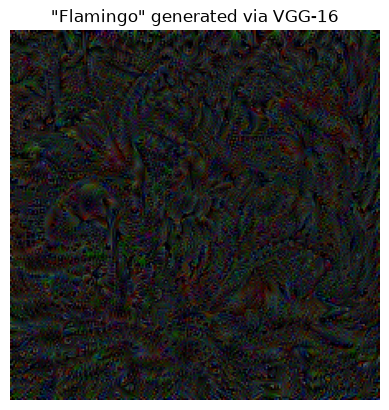

Generating Dumbbell #(20/20) via VGG-16


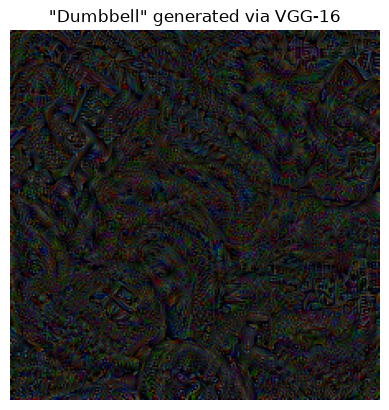

Generating Goldfish #(20/20) via VGG-19


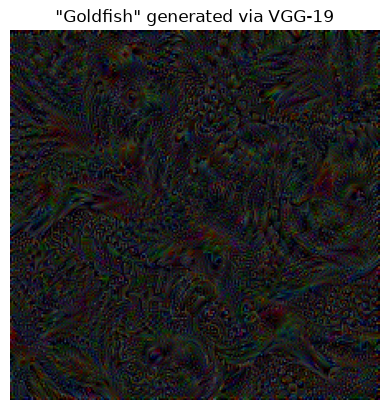

Generating Flamingo #(20/20) via VGG-19


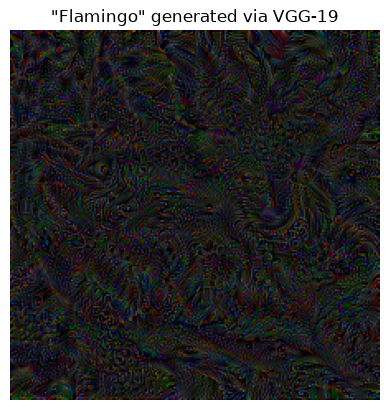

Generating Dumbbell #(20/20) via VGG-19


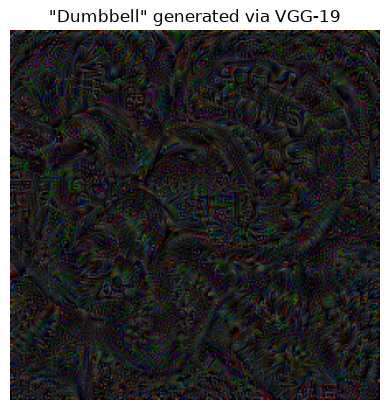

Generating Goldfish #(20/20) via ResNet-152


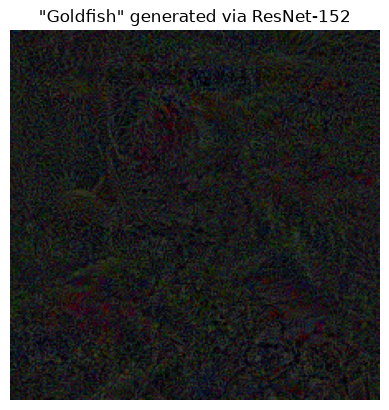

Generating Flamingo #(20/20) via ResNet-152


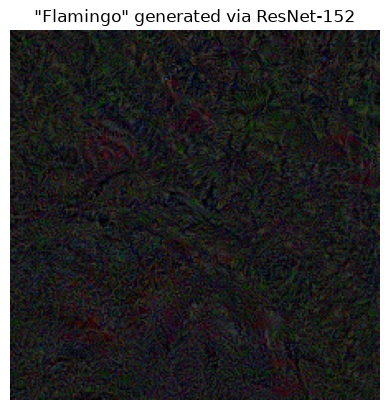

Generating Dumbbell #(20/20) via ResNet-152


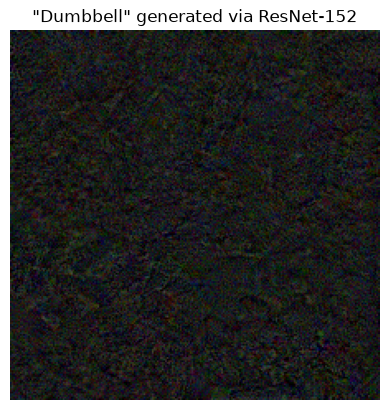

,Generator Model,Evaluator Model,Target Class,Mean Top-1 Correct,Mean Top-5 Correct,Mean Softmax Score
0,ResNet-152,ResNet-152,Dumbbell,1.00,1.00,0.999998
1,ResNet-152,ResNet-152,Flamingo,1.00,1.00,1.000000
2,ResNet-152,ResNet-152,Goldfish,1.00,1.00,1.000000
3,ResNet-152,VGG-16,Dumbbell,0.00,0.00,0.000479
4,ResNet-152,VGG-16,Flamingo,0.00,0.00,0.000345
5,ResNet-152,VGG-16,Goldfish,0.00,0.00,0.003309
6,ResNet-152,VGG-19,Dumbbell,0.00,0.00,0.000886
7,ResNet-152,VGG-19,Flamingo,0.00,0.00,0.001515
8,ResNet-152,VGG-19,Goldfish,0.00,0.05,0.005122
9,VGG-16,ResNet-152,Dumbbell,0.00,0.00,0.000205


In [12]:
models_dict = {
    "VGG-16": vgg_16,
    "VGG-19": vgg_19,
    "ResNet-152": resnet_152
}

target_classes = {
    "Goldfish": 1,
    "Flamingo": 130,
    "Dumbbell": 543
}

# Evaluate cross-model transferability for the above models and classes
df_rq1 = cross_model_transferability(
    models_dict=models_dict, 
    target_classes=target_classes,
    nr_images=20,
    init_img_scale=0.2,
    lr=0.003, # Default Adam learning rate seems to work well here.
    epochs=75,
    print_every=100,
    plot_images=True
)

# Output results
display(df_rq1)

## 6. RQ2 - Effect of optimization and regularization

To evaluate the effect of how different optimization and regularization techniques affect the visual quality of the generated feature visualizations and their cross-model transferability, we investigate a few regularization methods.

As seen in RQ1, the generated images for all three models result in high frequency noise, which seem to transfer between models to some extent in regards to VGG-16 and VGG-19 for some classes. This clearly happens as a result of the gradient ascent algorithm exploiting individual pixels' contribution to increasing the class logit score, by continuously increasing the pixel values. It would thus be reasonable to consider whether regularization techniques applied on the pixels would mitigate this effect, forcing the generated image to generate more semantically meaningful shapes or patterns, and whether or not this will increase the cross-model transferability alongside our subjective visual recognition of separate classes.

In particular, we explore the following regularization methods:
- **$L_2$ Regularization:** Regularizes the image by penalizing high pixel values by subtracting the maximization objective by $\lambda \Vert x \Vert_2^2$, mitigating the risk of individual pixels exploding.
- **Gaussian Blur Smoothing:** Regularizes the image after each gradient ascent iteration by redistributing nearby pixel values via a gaussian distribution for each pixel, reducing noise and smoothening shapes.

### 6.1 Visualization of Regularization on generated images

Before performing the cross-model transferability investigation (as in RQ1), with regularization enabled, we first demonstrate the individual effects of these regularization techniques on gradient ascent on VGG-16 in the cell below. We limit ourselves to only showing it for VGG-16 here, as these regularization methods will have similar results no matter the model. To ensure a fairer comparison, the torch randomizer seed is manually set to a fixed value $123$, such that each gradient ascent call uses identical starting images. Randomization is then restored prior to the cross-model transferability investigation.

Notably, in the output of the code block below we see that the unregularized result of performing gradient ascent on VGG-16 is a very noisy image with high pixel values (bright colors). When attempting to cross-transfer this image to VGG-19, we see a very low softmax score as a result. After applying $L_2$ regularization, we see the colors of the image pixels are significantly darker, and despite still being noisy, we can see some distinct features such as fish scales (for the goldfish class) that were difficult to see previously. The softmax score also jumped significantly such that VGG-19 would now be able to do a correct top-1 classification. If we instead apply gaussian blur smoothing, we see that the noise is greatly reduced, and distinct features such as scales can once again be seen. The colors are however significantly washed out as the extreme pixel values are distributed among each other. VGG-19's softmax score when applying gaussian blur smoothing is significantly higher than when using L2 smoothing, likely due to the reduction in noise which has overfitted to the peculiarities of the generator model. If both regularization techniques are used, we see the softmax score is nearly identical, but the washed out colors seen with gaussian blur alone is now reduced, making the colors more distinct while still reducing the noise, which ultimately makes the features more recognizable to us humans.

No regularization, evaluator model [VGG-19] softmax score: 0.00000
L2 regularization, evaluator model [VGG-19] softmax score: 0.72665
Gaussian Blur regularization, evaluator model [VGG-19] softmax score: 1.00000
L2 + Gaussian Blur regularization, evaluator model [VGG-19] softmax score: 1.00000


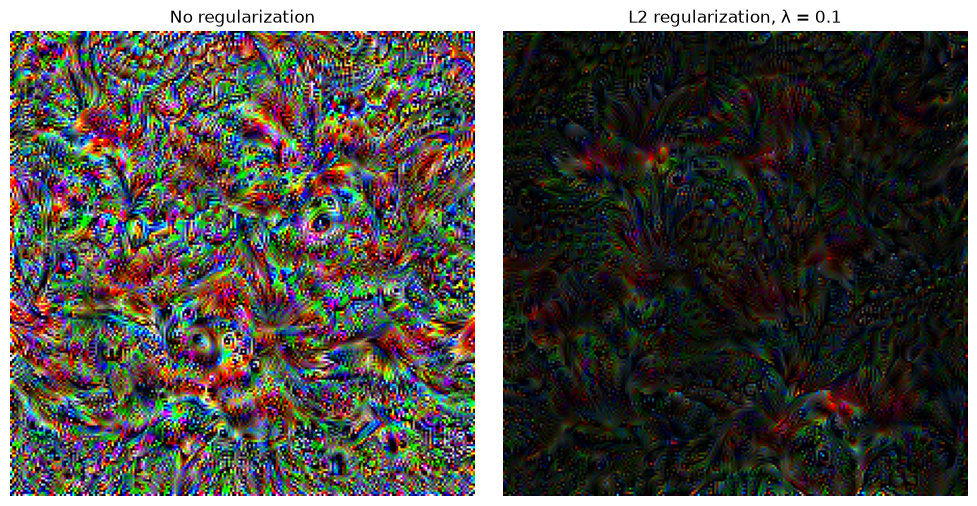

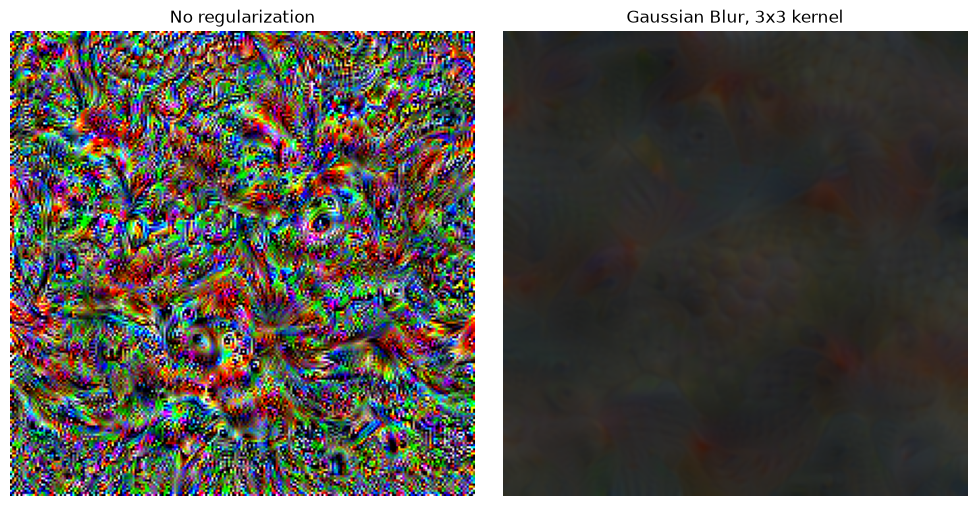

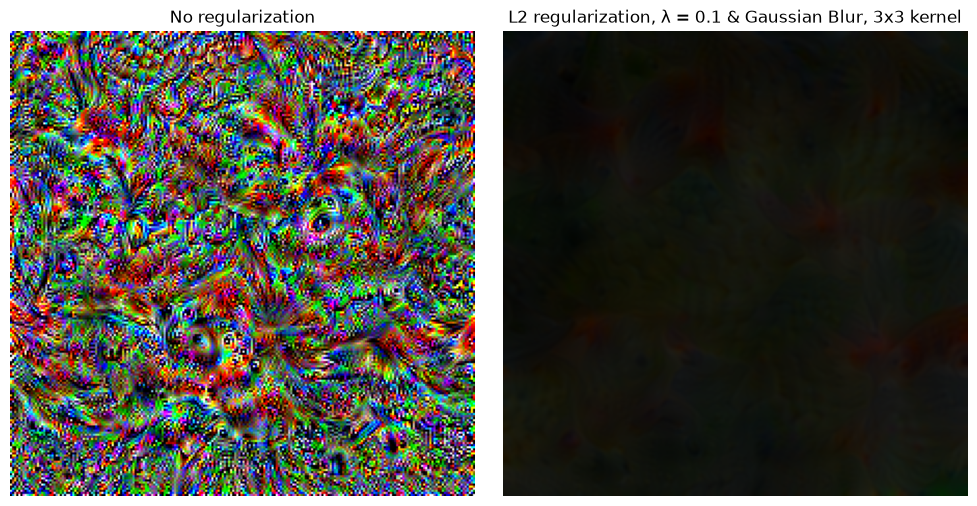

In [13]:
# Compare un-regularized with each regularization technique, and display side by side:

torch.manual_seed(123) # Manual seed to compare images from same starting point
target_label = 1 # Goldfish

# Perform gradient ascent on vgg_16 with no regularization, then with each regularization method & combination.
no_reg = gradient_ascent(vgg_16, target_label, init_img_scale=0.35, lr=0.005, epochs=400, print_every=500)
l2_reg = gradient_ascent(vgg_16, target_label, init_img_scale=0.35, lr=0.005, epochs=400, print_every=500, l2_lambda=0.1)
gauss_reg = gradient_ascent(vgg_16, target_label, init_img_scale=0.35, lr=0.005, epochs=400, print_every=500, gaussian_kernel_size=3)
l2_gauss_reg = gradient_ascent(vgg_16, target_label, init_img_scale=0.35, lr=0.005, epochs=400, print_every=500, l2_lambda=0.1, gaussian_kernel_size=3)

# Output cross-model transferability softmax scores for VGG-19 as evaluator model
print(f"No regularization, evaluator model [VGG-19] softmax score: {evaluate(vgg_19, no_reg, 1)['softmax_score']:.5f}")
print(f"L2 regularization, evaluator model [VGG-19] softmax score: {evaluate(vgg_19, l2_reg, 1)['softmax_score']:.5f}")
print(f"Gaussian Blur regularization, evaluator model [VGG-19] softmax score: {evaluate(vgg_19, gauss_reg, 1)['softmax_score']:.5f}")
print(f"L2 + Gaussian Blur regularization, evaluator model [VGG-19] softmax score: {evaluate(vgg_19, l2_gauss_reg, 1)['softmax_score']:.5f}")

# Plot comparisons
plot_tensor_pair(no_reg, l2_reg, "No regularization", "L2 regularization, λ = 0.1")
plot_tensor_pair(no_reg, gauss_reg, "No regularization", "Gaussian Blur, 3x3 kernel")
plot_tensor_pair(no_reg, l2_gauss_reg, "No regularization", "L2 regularization, λ = 0.1 & Gaussian Blur, 3x3 kernel")

# Restore random seed
torch.seed();

### 6.2 Cross-model transferability of regularized images

Now that we have analyzed the visual effects of individual regularization techniques, with only a simple quantitative analysis to go alongside it, let us now do a full cross-model transferability investigation as for RQ1.

In the code cell below, we execute the `cross_model_transferability` function across all models and classes used in the RQ1 experiment, using both $L_2$ regularization and Gaussian Blur smoothing. This allows us to evaluate whether regularizing the generated images increases or decreases the cross-model transferability for each of the three models.

The hyperparameters for RQ2 will be manually and iteratively set independently of those used in RQ1. This is of course due to the fact that regularization ensures the pixel values can not explode or overfit as greatly to the generator model, which makes it feasible to both start with higher initial noise, and train for more epochs. In regards to the regularization hyperparameters, we expect low values of $\lambda$ for $L_2$ to be suitable, as to not get images that are too dark, as we sum the squares of *each pixel*, which results in incredibly large penalties for large $\lambda$. The gaussian kernel size should also be kept small, at either $3 \times 3$ or $5 \times 5$, as the images we are generating are not of high enough resolution to use larger kernels without applying too much smoothing and washing out important features for human interpretability. As the noise is very high frequency, it's also sensible to use smaller kernels to not eliminate smaller features in the image.

Comparing the results of `cross_model_transferability` in the code block below with the unregularized findings in RQ1, several insights are revealed:
- VGG-16 and VGG-19 still achieve high cross-model transferability across all classes, benefiting even further from the reduced noise and improved visual coherence compared to what was obtained in RQ1.
- In RQ1, ResNet-152 and VGG models had next to no cross-model transferability. With regularization enabled, this seems to not be the case. Images generated by ResNet-152 achieve strong cross-transferability when evaluated by VGG-16 and VGG-19 for classes like *Goldfish* and *Flamingo*.
- Furthermore, the inverse direction also seems to give great results. Images generated by the VGG models successfully transfer to ResNet-152 for *Goldfish* and *Dumbbell*. This indicates that the regularization techniques strips away much of the model-specific noise and forces the optimization to capture more generalized semantic structures which happen to be better interpreted by other architectures trained on the same dataset.
- While transferability improves a lot between ResNet and the VGG models, some specific classes seem to still be quite challenging to transfer between these architectures. Notably, *Dumbbell* when generated by ResNet-152 and evaluated by VGG models or *Flamingo* when generated by the VGG models and evaluated by ResNet-152 gives noticeably poorer results than the other classes. This suggests that certain features may differ more fundamentally between the two architectures, such that when they are generated even with regularization to reduce pixel saturation or noise, they remain more unfamiliar to the evaluator model than the other classes.

Generating Goldfish #(20/20) via VGG-16


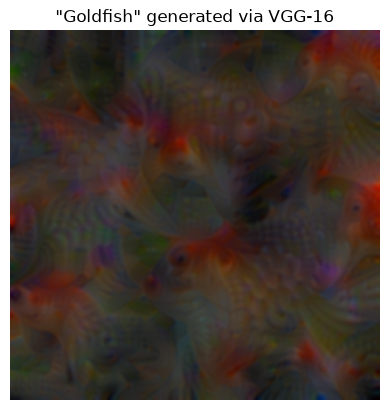

Generating Flamingo #(20/20) via VGG-16


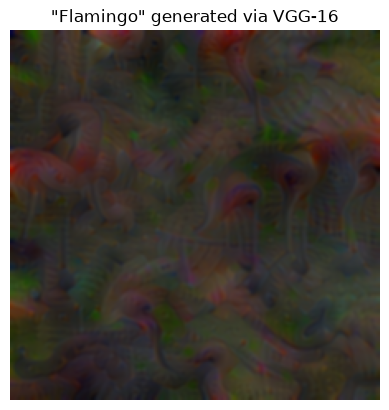

Generating Dumbbell #(20/20) via VGG-16


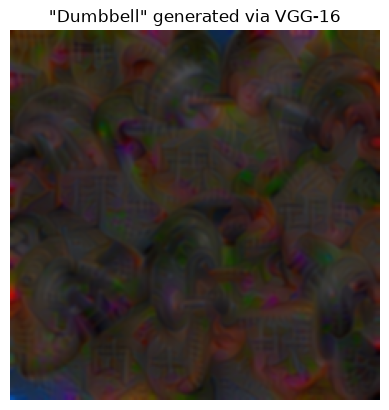

Generating Goldfish #(20/20) via VGG-19


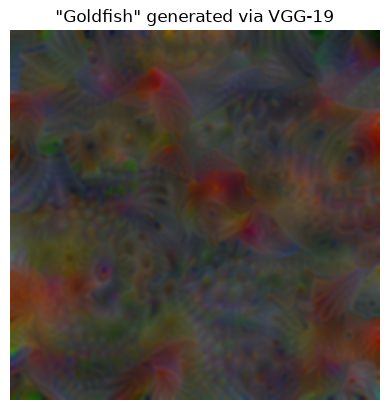

Generating Flamingo #(20/20) via VGG-19


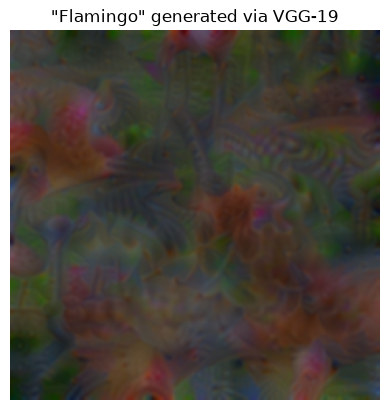

Generating Dumbbell #(20/20) via VGG-19


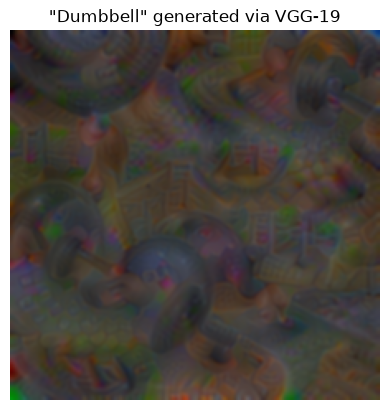

Generating Goldfish #(20/20) via ResNet-152


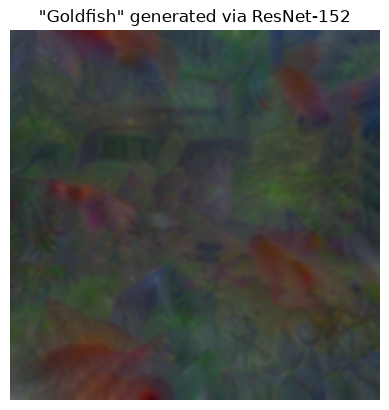

Generating Flamingo #(20/20) via ResNet-152


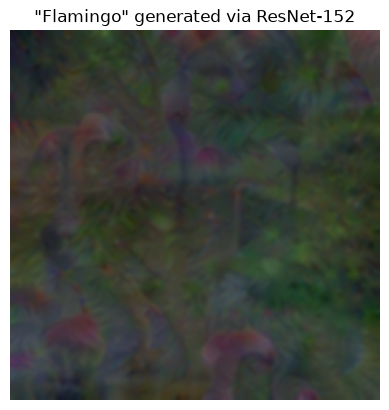

Generating Dumbbell #(20/20) via ResNet-152


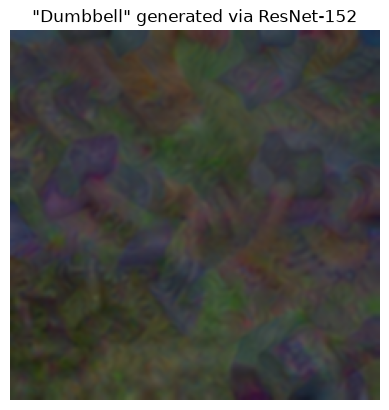

,Generator Model,Evaluator Model,Target Class,Mean Top-1 Correct,Mean Top-5 Correct,Mean Softmax Score
0,ResNet-152,ResNet-152,Dumbbell,1.00,1.00,1.000000
1,ResNet-152,ResNet-152,Flamingo,1.00,1.00,1.000000
2,ResNet-152,ResNet-152,Goldfish,1.00,1.00,1.000000
3,ResNet-152,VGG-16,Dumbbell,0.00,0.00,0.000496
4,ResNet-152,VGG-16,Flamingo,0.90,1.00,0.486305
5,ResNet-152,VGG-16,Goldfish,1.00,1.00,0.731102
6,ResNet-152,VGG-19,Dumbbell,0.05,0.05,0.002980
7,ResNet-152,VGG-19,Flamingo,0.50,0.95,0.261394
8,ResNet-152,VGG-19,Goldfish,1.00,1.00,0.753716
9,VGG-16,ResNet-152,Dumbbell,1.00,1.00,0.945819


In [14]:
models_dict = {
    "VGG-16": vgg_16,
    "VGG-19": vgg_19,
    "ResNet-152": resnet_152
}

target_classes = {
    "Goldfish": 1,
    "Flamingo": 130,
    "Dumbbell": 543
}

# Evaluate cross-model transferability for the above models and classes
df_rq2 = cross_model_transferability(
    models_dict=models_dict, 
    target_classes=target_classes,
    nr_images=20,
    init_img_scale=0.5,
    lr=0.05,
    epochs=200,
    print_every=1000,
    plot_images=True,
    l2_lambda=0.001,
    gaussian_kernel_size=5
)

# Output results
display(df_rq2)

## 7. Results, interpretation and conclusions

This section summarizes the findings from our research into cross-model transferability of features generated via gradient ascent (RQ1) and the role of optimization and regularization in improving transferability and human interpretability (RQ2), evaluating our initial hypotheses and summarizing the core takeaways of the project.

### 7.1 Summary of quantitative metrics

To summarize and compare performance across architectures and evaluate the impact of adding regularization to gradient ascent, the following tables summarize our findings by simplifying the results, where numerical ranges show the worst results for any investigated class, to the best out of any investigated class:

#### Table 1: Unregularized Cross-model transferability (RQ1)

| Generator Model | Evaluator Model | Mean Top-1 Accuracy | Mean Top-5 Accuracy | Mean Softmax Score | Interpretation |
|---|---|---|---|---|---|
| **VGG-16** | **VGG-19** | 0.20 - 0.55 | 0.50 - 1.00 | 0.20 - 0.39 | Moderate transferability, partial success for VGG-16 features interpreted by VGG-19 |
| **VGG-16** | **ResNet-152** | 0.00 | 0.00 | 0.0000 - 0.0004 | Extremely poor, near-zero accuracy and random guessing scores |
| **VGG-19** | **VGG-16** | 0.00 - 0.65 | 0.25 - 0.95 | 0.01 - 0.61 | Low to moderate transferability, highly class-dependent |
| **VGG-19** | **ResNet-152** | 0.00 | 0.00 | 0.0000 - 0.0013 | Extremely poor, near-zero accuracy and random guessing scores |
| **ResNet-152** | **VGG-16** | 0.00 | 0.00 | 0.0003 - 0.0033 | Extremely poor, near-zero accuracy and random guessing scores |
| **ResNet-152** | **VGG-19** | 0.00 | 0.00 - 0.05 | 0.0009 - 0.0051 | Extremely poor, near-zero accuracy and random guessing scores |

#### Table 2: Regularized ($L_2$ + Gaussian Blur) Cross-model transferability (RQ2)

| Generator Model | Evaluator Model | Mean Top-1 Accuracy | Mean Top-5 Accuracy | Mean Softmax Score | Interpretation |
|---|---|---|---|---|---|
| **VGG-16** | **VGG-19** | 0.90 - 1.00 | 1.00 | 0.84 - 1.00 | Excellent cross-model transferability |
| **VGG-16** | **ResNet-152** | 0.10 - 1.00 | 0.65 - 1.00 | 0.16 - 0.95 | Excellent besides a few outlier classes (e.g. Flamingo) which have poor/moderate transferability |
| **VGG-19** | **VGG-16** | 0.75 - 1.00 | 1.00 | 0.75 - 1.00 | Excellent cross-model transferability |
| **VGG-19** | **ResNet-152** | 0.25 - 1.00 | 0.80 - 1.00 | 0.22 - 0.97 | Excellent besides a few outlier classes (e.g. Flamingo) which have moderate transferability |
| **ResNet-152** | **VGG-16** | 0.00 - 1.00 | 0.00 - 1.00 | 0.00 - 0.73 | Excellent besides a few outlier classes (e.g. Dumbbell) which have very poor transferability |
| **ResNet-152** | **VGG-19** | 0.05 - 1.00 | 0.05 - 1.00 | 0.002 - 0.75 | Excellent besides a few outlier classes (e.g. Dumbbell) which have very poor transferability |

### 7.2 Conclusions and Hypothesis Evaluation

1. **RQ1: Cross-model transferability.** To what extent do class-specific feature visualizations
transfer between pretrained CNN models with similar and different architectures?

- Our initial hypothesis was that visualizations will transfer better between VGG-16 and VGG-19 than between any VGG models and ResNet-152 as the former two are architecturally similar. The results confirm that this is true. Even without regularization, the tables above show that class-specific visualisations generated via VGG-16 and VGG-19 transferred significantly better between the two models than between any of the VGG models and ResNet-152. Without regularization, cross-model transferability for models with significantly different architectures seems to be  virtually nonexistent by our results.

2. **RQ2: Effect of optimization and regularization.** How do different gradient-ascent optimization
and regularization methods affect the visual characteristics and cross-model transferability of the
generated visualizations?

- Our findings are that the addition of $L_2$ regularization and Gaussian blur smoothing successfully makes the otherwise noisy images more interpretable for us humans, but surprisingly also for the models, regardless of architectural differences between the VGG models and ResNet-152. By removing the high-frequency noise generated by the pixels overfitting to their generator model, the gradient ascent algorithm was forced to generate much clearer semantic features which seem to be more model-agnostic than the unregularized noise generated when investigating RQ1.

- There are a few exceptions to the above findings for RQ2. Namely that certain classes (e.g. *Dumbbell* or *Flamingo*) seem to be much more difficult to generalize and transfer between models of different architectures (VGG models to ResNet-152, or vice versa). This highlights that there must be some features that the different architectures have encoded much differently from the others, which shows that creating a perfect bridge for cross-model interpretability may be feasible for certain classes, but would be difficult to achieve for all. Consequently this implies that it may vary a lot on a case-by-case basis.